# The Variational Quantum Eigensolver (VQE) — an interactive lecture

**Who this is for.** You know the basics of quantum mechanics (states, operators, expectation values, measurement). You do *not* need to know quantum computing, optimization theory, or quantum chemistry. We'll build those up as we go.

**How to use it.** Run the cells from top to bottom. Wherever you see sliders, **play with them** — that's where the intuition comes from.

**The plan**

| Part | Topic | Quantum? |
|---|---|---|
| 1 | What is an optimization problem? (1 and 2 parameters) | no |
| 2 | How do we solve one? Gradient descent and friends | no |
| 3 | A qubit whose *energy* we minimize by tuning two circuit parameters (Qiskit) | yes |
| 4 | The variational principle → VQE for the hydrogen molecule H₂ | yes |
| 5 | A molecule that needs several parameters (HeH⁺) | yes |

**The one-sentence version of VQE:**
> *Guess a quantum state with some adjustable knobs. Ask a quantum computer for its energy. Let a normal computer turn the knobs to lower that energy. Repeat.*



In [ ]:
# If something is missing, uncomment and run:
%pip install numpy scipy matplotlib ipywidgets pylatexenc qiskit pyscf qiskit_nature 

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import ipywidgets as widgets
from ipywidgets import interact, interact_manual, FloatSlider, IntSlider, Checkbox, SelectionSlider, Dropdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
BLUE, ORANGE, GREEN, RED, GRAY = "#2a6fdb", "#f28c28", "#2e9e5b", "#d64545", "#777777"
rng = np.random.default_rng(7)      # fixed seed so "random" results are reproducible
print("Ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 28.1 MB/s eta 0:00:00
Ready.


---
# Part 1 · Optimization: finding the lowest point

### What is an optimization problem?

1. You are given a function with some parameters. Example: $f(x,y) = 0.1\,x^2 + \sin(2y) + 3 \log(x)$. Here $x,y$ are parameters. The function $f$ is called a **cost function**.

2. **Parameters** are numbers we are free to choose (the "knobs").

2. **Goal** : Tune the parameters (or control the "knobs") to make the cost function as **small** as possible.


Think of hiking in fog: the parameters are your position, the cost is your altitude, and you want to reach the lowest valley.

## 1.1 One parameter

Below is a cost function of a single parameter $x$:

$$f(x) = 0.1\,x^2 + \sin(2x).$$

**Drag the slider** and watch the orange dot. Try to find the lowest point by hand. Notice there are *several* valleys: some are only **local minima** (lowest in their neighbourhood), and one is the **global minimum** (lowest overall).

In [2]:
def f1(x):
    return 0.1 * x**2 + np.sin(2 * x)

xs = np.linspace(-6, 6, 800)

def show_1d(x=3.5, reveal=False):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(xs, f1(xs), color=BLUE, lw=2)
    ax.axvline(x, color=GRAY, ls=":")
    ax.plot([x], [f1(x)], "o", ms=13, color=ORANGE, zorder=5)
    if reveal:
        i = np.argmin(f1(xs))
        ax.plot(xs[i], f1(xs[i]), "*", ms=20, color=GREEN, label=f"global minimum  f = {f1(xs[i]):.3f}")
        ax.legend(loc="upper center")
    ax.set_xlabel("parameter  x"); ax.set_ylabel("cost  f(x)")
    ax.set_ylim(-1.6, 5.2)
    ax.set_title(f"x = {x:+.2f}      f(x) = {f1(x):+.3f}")
    plt.show()

interact(show_1d,
         x=FloatSlider(min=-6, max=6, step=0.05, value=3.5, description="x", continuous_update=True, layout=widgets.Layout(width="600px")),
         reveal=Checkbox(value=False, description="reveal the global minimum"));

interactive(children=(FloatSlider(value=3.5, description='x', layout=Layout(width='600px'), max=6.0, min=-6.0,…

## 1.2 Two parameters

With two parameters the cost function is a **surface**: the height above the point $(x, y)$ is $f(x,y)$. We'll use

$$f(x,y) = 0.1\,(x^2+y^2) + \sin(x)\cos(y).$$

Two views of the same function are shown:

* **left**: a 3D surface (altitude = cost),
* **right**: a **contour map** (like a hiking map; dark = low, bright = high). Contour maps are how we'll draw optimization problems from now on.

Move both sliders. There are two valleys here — can you find both?

In [3]:
def f2(x, y):
    return 0.1 * (x**2 + y**2) + np.sin(x) * np.cos(y)

g = np.linspace(-5, 5, 90)
GX, GY = np.meshgrid(g, g)
GZ = f2(GX, GY)

def show_2d(x=3.0, y=2.0, reveal=False):
    fig = plt.figure(figsize=(12, 4.8))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot_surface(GX, GY, GZ, cmap="viridis", alpha=0.75, linewidth=0, antialiased=True)
    zmin = GZ.min() - 0.2
    ax.plot([x, x], [y, y], [zmin, f2(x, y)], color=ORANGE, lw=1.5)
    ax.scatter([x], [y], [f2(x, y)], color=ORANGE, s=80, depthshade=False)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f"); ax.view_init(28, -55)
    ax.set_title(f"f({x:+.2f}, {y:+.2f}) = {f2(x, y):+.3f}")

    ax2 = fig.add_subplot(1, 2, 2)
    cs = ax2.contourf(GX, GY, GZ, 30, cmap="viridis")
    ax2.contour(GX, GY, GZ, 15, colors="white", linewidths=0.3)
    fig.colorbar(cs, ax=ax2, label="cost f")
    ax2.plot([x], [y], "o", ms=13, color=ORANGE, mec="white", mew=1.5)
    if reveal:
        i = np.unravel_index(np.argmin(GZ), GZ.shape)
        ax2.plot(GX[i], GY[i], "*", ms=20, color=GREEN, mec="white", label="global minimum")
        ax2.legend(loc="upper right")
    ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_aspect("equal"); ax2.grid(False)
    plt.tight_layout(); plt.show()

interact(show_2d,
         x=FloatSlider(min=-5, max=5, step=0.1, value=3.0, description="x"),
         y=FloatSlider(min=-5, max=5, step=0.1, value=2.0, description="y"),
         reveal=Checkbox(value=False, description="reveal the global minimum"));

interactive(children=(FloatSlider(value=3.0, description='x', max=5.0, min=-5.0), FloatSlider(value=2.0, descr…

---
# Part 2 · How do we actually minimize?

## 2.1 A zoo of optimizers

Optimizers fall into two broad families.

**Gradient-based** — use the slope of the landscape.
* *Gradient descent*: step downhill. Simple and the basis of everything else.
* *Momentum / Adam*: gradient descent with "memory", like a heavy ball rolling.
* *BFGS / L-BFGS*: also builds an estimate of the curvature.

**Gradient-free** — only need to *evaluate* $f$, never its slope.
* *Nelder–Mead*: moves a little triangle (simplex) around the landscape.
* *COBYLA*: builds local linear models of $f$.
* *SPSA*: estimates a slope from only 2 random evaluations — popular on noisy quantum hardware.

**Why does this matter for quantum computing?** On a quantum computer, every evaluation of $f$ costs resource (time and money) and is *noisy*. So we care about (i) how many evaluations an optimizer needs and (ii) whether it survives noise. But we will talk more about it later.

## 2.2 Gradient descent

The slope (gradient) tells us which way is uphill, so we walk the opposite way:

$$\boxed{\;\vec\theta_{\text{new}} = \vec\theta_{\text{old}} - \eta\,\nabla f(\vec\theta_{\text{old}})\;}$$

$\eta$ is the **learning rate** (step size). Too small → painfully slow. Too large → you overshoot and bounce around or blow up.

**Try it (1D).** Pick a start point and learning rate. Things to try:
* $\eta = 0.05$ vs $0.15$ vs $0.35$ (what happens at $0.35$?),
* different starting points — which valley do you end in?

In [4]:
def df1(x):
    return 0.2 * x + 2 * np.cos(2 * x)

def gd(grad, p0, lr, steps):
    path = [np.array(p0, float)]
    for _ in range(steps):
        path.append(path[-1] - lr * grad(path[-1]))
    return np.array(path)

def show_gd_1d(x0=3.5, lr=0.1, steps=15):
    path = gd(lambda p: df1(p), [x0], lr, steps)[:, 0]
    path = np.clip(path, -12, 12)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
    ax.plot(xs, f1(xs), color=BLUE, lw=2)
    ax.plot(path, f1(path), "-", color=ORANGE, alpha=0.5)
    sc = ax.scatter(path, f1(path), c=np.arange(len(path)), cmap="autumn_r", s=45, zorder=5, edgecolor="k", linewidth=0.4)
    ax.plot(path[0], f1(path[0]), "s", color="k", ms=9, label="start")
    ax.set_xlim(-6, 6); ax.set_ylim(-1.6, 5.2); ax.set_xlabel("x"); ax.set_ylabel("f(x)"); ax.legend()
    ax.set_title("path of gradient descent (dark = later)")
    ax2.plot(f1(path), "o-", color=ORANGE)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("f(x)"); ax2.set_title(f"final f = {f1(path[-1]):.3f}")
    plt.tight_layout(); plt.show()

interact(show_gd_1d,
         x0=FloatSlider(min=-6, max=6, step=0.1, value=-2.0, description="start x"),
         lr=FloatSlider(min=0.01, max=0.6, step=0.01, value=0.1, description="rate η"),
         steps=IntSlider(min=0, max=60, step=1, value=15, description="steps"));

interactive(children=(FloatSlider(value=-2.0, description='start x', max=6.0, min=-6.0), FloatSlider(value=0.1…

In [5]:
def grad_f2(p):
    x, y = p
    return np.array([0.2 * x + np.cos(x) * np.cos(y), 0.2 * y - np.sin(x) * np.sin(y)])

def show_gd_2d(x0=3.0, y0=2.0, lr=0.3, steps=25):
    path = gd(grad_f2, [x0, y0], lr, steps)
    path = np.clip(path, -5, 5)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
    cs = ax.contourf(GX, GY, GZ, 30, cmap="viridis")
    ax.contour(GX, GY, GZ, 15, colors="white", linewidths=0.3)
    ax.plot(path[:, 0], path[:, 1], "-", color=ORANGE, lw=2)
    ax.scatter(path[:, 0], path[:, 1], c=np.arange(len(path)), cmap="autumn_r", s=30, edgecolor="k", linewidth=0.4, zorder=5)
    ax.plot(*path[0], "s", color="w", mec="k", ms=10, label="start"); ax.plot(*path[-1], "o", color=RED, mec="w", ms=10, label="end")
    ax.legend(loc="upper right"); ax.set_aspect("equal"); ax.grid(False); ax.set_xlabel("x"); ax.set_ylabel("y")
    vals = [f2(*p) for p in path]
    ax2.plot(vals, "o-", color=ORANGE); ax2.set_xlabel("iteration"); ax2.set_ylabel("f(x, y)")
    ax2.set_title(f"final f = {vals[-1]:.2f}   (global min ≈ {GZ.min():.2f})")
    plt.tight_layout(); plt.show()

interact(show_gd_2d,
         x0=FloatSlider(min=-5, max=5, step=0.1, value=3.0, description="start x"),
         y0=FloatSlider(min=-5, max=5, step=0.1, value=2.0, description="start y"),
         lr=FloatSlider(min=0.01, max=1.2, step=0.01, value=0.3, description="rate η"),
         steps=IntSlider(min=0, max=80, step=1, value=25, description="steps"));

interactive(children=(FloatSlider(value=3.0, description='start x', max=5.0, min=-5.0), FloatSlider(value=2.0,…

## 2.3 Comparing optimizers by the number of function evaluations

Here we run three off-the-shelf optimizers from `scipy` from the same starting point, and count how many times each one had to *evaluate* $f$. (On a quantum computer each evaluation = running circuits many times, so this count is the real price tag.) Notice that all three end up in the same *local* minimum (f ≈ 0.02), not the global one (f ≈ −0.79) — the starting point decided that.

In [6]:
def run_scipy(method, start=(-0.5, 1.0)):
    calls = []
    def f(p):
        calls.append(1)
        return f2(*p)
    kw = {"jac": grad_f2} if method == "BFGS" else {}
    res = minimize(f, start, method=method, **kw)
    return res, len(calls)

print(f"{'method':14s} {'needs gradient?':16s} {'evaluations of f':17s} {'found (x, y)':20s} f")
for m, needs_grad in [("Nelder-Mead", "no"), ("COBYLA", "no"), ("BFGS", "yes")]:
    res, n = run_scipy(m)
    print(f"{m:14s} {needs_grad:16s} {n:<17d} ({res.x[0]:+.3f}, {res.x[1]:+.3f})      {res.fun:+.4f}")

method         needs gradient?  evaluations of f  found (x, y)         f
Nelder-Mead    no               77                (-1.306, +0.000)      -0.7946
COBYLA         no               38                (-1.306, -0.000)      -0.7946
BFGS           yes              7                 (-1.306, -0.000)      -0.7946


**Key takeaways of Part 2**
* Optimizers walk downhill using slopes (or estimates of them).
* They can get stuck in **local minima**, so the starting point matters.
* Every evaluation of the cost has a price — on a quantum computer, a *high* one.

Now we make the cost function quantum.

---
# Part 3 · A quantum cost function: the energy of a qubit

From here on we use **[Qiskit](https://qiskit.org)**, IBM's open-source quantum computing toolkit, for everything quantum: building circuits, simulating them, "measuring" them and computing energies. The plotting and the optimizers are still matplotlib and SciPy.

## 3.1 Energy as a cost function

In quantum mechanics, the **Hamiltonian** $H$ is the operator for energy. If a system is in state $|\psi\rangle$, its average energy is the expectation value

$$E = \langle\psi|H|\psi\rangle .$$

The **ground state** is the state with the lowest possible energy, $E_0$ — the lowest eigenvalue of $H$. So:

> **Finding a ground state = minimizing $E(\psi)=\langle\psi|H|\psi\rangle$ over states $|\psi\rangle$.**

That is exactly an optimization problem. The cost function is the energy. The only new thing is: what are the "knobs"?

## 3.2 Knobs = parameters of a quantum circuit

A **parametrized quantum circuit** prepares a state using gates that contain adjustable angles. We'll use a single qubit and just two gates, $R_y(\theta)$ and $R_z(\varphi)$ — rotations of the qubit's Bloch vector. In Qiskit the angles are `Parameter` objects: placeholders that we fill in with numbers later.

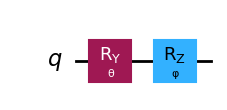

In [7]:
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector, Pauli, random_statevector
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)   # harmless SciPy notices triggered inside Qiskit
from qiskit.primitives import StatevectorEstimator, BackendEstimatorV2
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.circuit.library import PauliEvolutionGate
from qiskit import transpile
from qiskit.visualization import plot_histogram

def show_circuit(qc):
    """Draw a circuit nicely (matplotlib drawer if available, plain text otherwise)."""
    try:
        fig = qc.draw("mpl"); display(fig); plt.close(fig)
    except Exception:
        print(qc.draw("text"))

theta, phi = Parameter("θ"), Parameter("φ")
qc1 = QuantumCircuit(1)          # one qubit, starts in |0>
qc1.ry(theta, 0)                 # rotate about the y-axis by θ
qc1.rz(phi, 0)                   # rotate about the z-axis by φ
qc1.draw("mpl")

Starting from $|0\rangle$ this circuit makes (up to an unobservable global phase)

$$|\psi(\theta,\varphi)\rangle = \cos\tfrac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\,|1\rangle ,$$

which is just the point on the **Bloch sphere** with polar angle $\theta$ and azimuth $\varphi$. So the two parameters literally steer a point on a sphere — *changing the parameters = moving the state*.

Our Hamiltonian will be

$$H = 0.6\,Z + 0.8\,X .$$

Qiskit represents Hamiltonians as a weighted sum of Pauli strings, `SparsePauliOp`. The true ground energy is $E_0=-1$ — having the answer in advance lets us check our work.

To get the energy $\langle\psi(\theta,\varphi)|H|\psi(\theta,\varphi)\rangle$ we use Qiskit's **Estimator** primitive: you give it a circuit, an observable and parameter values; it returns the expectation value.

In [8]:
H1 = SparsePauliOp.from_list([("Z", 0.6), ("X", 0.8)])      # our Hamiltonian
print(H1)

estimator = StatevectorEstimator()       # exact simulator: the "infinite shots" limit

def energy1(t, p):
    """Cost function: <psi(t,p)| H1 |psi(t,p)>.  Parameter order = qc1.parameters = (θ, φ)."""
    return float(estimator.run([(qc1, H1, [t, p])]).result()[0].data.evs)

def state1(t, p):
    return Statevector(qc1.assign_parameters({theta: t, phi: p}))

def bloch_vec(t, p):
    """Bloch vector (<X>, <Y>, <Z>) of the state, computed with Qiskit."""
    sv = state1(t, p)
    return np.array([sv.expectation_value(Pauli(c)).real for c in "XYZ"])

print("Order of circuit parameters:", qc1.parameters)
print("Exact ground energy E0 =", np.linalg.eigvalsh(H1.to_matrix())[0])
print("Cost at (θ, φ) = (0, 0), i.e. state |0>:", energy1(0, 0), " (should be 0.6, since <Z>=1 and <X>=0)")

SparsePauliOp(['Z', 'X'],
              coeffs=[0.6+0.j, 0.8+0.j])
Order of circuit parameters: ParameterView([Parameter(θ), Parameter(φ)])
Exact ground energy E0 = -1.0
Cost at (θ, φ) = (0, 0), i.e. state |0>: 0.6  (should be 0.6, since <Z>=1 and <X>=0)


## 3.3 What does the energy landscape look like?

Because the state is just a point on the Bloch sphere, the energy is a function of that point. With our $H$ it works out to

$$E(\theta,\varphi) = 0.6\cos\theta + 0.8\sin\theta\cos\varphi ,$$

i.e. $E = \vec h\cdot\vec r$, where $\vec r$ is the Bloch vector of the state and $\vec h=(0.8,0,0.6)$. The energy is lowest when the Bloch vector points **opposite** to $\vec h$ (green arrow).

**Play with the sliders.** The left panel is the Bloch sphere (orange arrow = your state, green arrow = the ground-state direction). The right panel is the energy landscape over the two parameters — the exact same kind of contour map as in Part 1, only now the height is a *physical energy*. (We compute the whole map in one go by handing the Estimator thousands of parameter values.)

In [9]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

def draw_bloch(ax, vec, ground_dir=None, path=None):
    """Bloch sphere with arrows. (Qiskit's plot_bloch_vector draws one static vector; we want arrows + a path.)"""
    u, v = np.linspace(0, 2*np.pi, 40), np.linspace(0, np.pi, 20)
    ax.plot_surface(np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v)),
                    color="lightsteelblue", alpha=0.10, linewidth=0)
    t = np.linspace(0, 2*np.pi, 100)
    for xyz in [(np.cos(t), np.sin(t), 0*t), (np.cos(t), 0*t, np.sin(t)), (0*t, np.cos(t), np.sin(t))]:
        ax.plot(*xyz, color=GRAY, lw=0.5)
    for (a, b, c, s) in [(0, 0, 1.25, "|0⟩"), (0, 0, -1.3, "|1⟩"), (1.3, 0, 0, "x"), (0, 1.3, 0, "y")]:
        ax.text(a, b, c, s, ha="center", fontsize=11)
    if ground_dir is not None:
        ax.quiver(0, 0, 0, *ground_dir, color=GREEN, lw=3, arrow_length_ratio=0.12)
    if path is not None:
        ax.plot(path[:, 0], path[:, 1], path[:, 2], ".-", color=RED, lw=1.5, ms=5)
    ax.quiver(0, 0, 0, *vec, color=ORANGE, lw=4, arrow_length_ratio=0.15)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.view_init(18, 40)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)

h_vec = np.array([0.8, 0.0, 0.6])
ground_dir = -h_vec / np.linalg.norm(h_vec)

# Energy on a whole grid of (θ, φ) values, in ONE Estimator call (parameter values broadcast)
TH, PH = np.meshgrid(np.linspace(0, np.pi, 60), np.linspace(0, 2*np.pi, 120))
grid_params = np.stack([TH.ravel(), PH.ravel()], axis=-1)
E_grid = estimator.run([(qc1, H1, grid_params)]).result()[0].data.evs.reshape(TH.shape)
closed_form = 0.6*np.cos(TH) + 0.8*np.sin(TH)*np.cos(PH)
print("max |Qiskit − closed form| =", np.abs(E_grid - closed_form).max(), " (valid for the original H)")

def draw_landscape(ax, theta_, phi_):
    cs = ax.contourf(TH, PH, E_grid, 30, cmap="coolwarm")
    ax.contour(TH, PH, E_grid, 15, colors="white", linewidths=0.3)
    ax.figure.colorbar(cs, ax=ax, label="energy ⟨H⟩")
    ax.plot([theta_], [phi_], "o", ms=13, color=ORANGE, mec="k", mew=1.5)
    ax.set_xlabel("θ  (parameter 1)"); ax.set_ylabel("φ  (parameter 2)"); ax.grid(False)

def show_qubit(theta_=0.5, phi_=1.0):
    p0, p1 = state1(theta_, phi_).probabilities()
    fig = plt.figure(figsize=(12, 4.8))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    draw_bloch(ax, bloch_vec(theta_, phi_), ground_dir)
    ax.set_title(f"state: {p0:.2f}|0⟩ + {p1:.2f}|1⟩ (probabilities)")
    ax2 = fig.add_subplot(1, 2, 2)
    draw_landscape(ax2, theta_, phi_)
    ax2.set_title(f"E(θ={theta_:.2f}, φ={phi_:.2f}) = {energy1(theta_, phi_):+.3f}      (exact minimum = −1)")
    plt.tight_layout(); plt.show()

interact(show_qubit,
         theta_=FloatSlider(min=0, max=np.pi, step=0.02, value=0.5, description="θ"),
         phi_=FloatSlider(min=0, max=2*np.pi, step=0.02, value=1.0, description="φ"));

max |Qiskit − closed form| = 4.440892098500626e-16  (valid for the original H)


interactive(children=(FloatSlider(value=0.5, description='θ', max=3.141592653589793, step=0.02), FloatSlider(v…

Things to notice:

* Moving $\theta$ slides the state from the north pole $|0\rangle$ to the south pole $|1\rangle$; moving $\varphi$ spins it around the vertical axis.
* The energy reaches $-1$ only when the orange arrow lies right on top of the green one. The minimum on the map is at $\theta\approx 2.21$, $\varphi=\pi$.
* **Optimizing = steering the orange arrow until it lines up with the green arrow**, without ever being told where the green arrow is. The optimizer only sees the number $E$.

## 3.4 "The evaluation is done on a quantum computer"

So far Qiskit's Estimator gave us exact energies from the wavefunction, which a real quantum computer can't do. All you can do on hardware is **prepare the state and measure it**, each time getting one random bit per qubit. So how do we get $\langle H\rangle$?

Write $H$ as a sum of simple pieces (Pauli strings) and use linearity:

$$\langle H\rangle = 0.6\,\langle Z\rangle + 0.8\,\langle X\rangle .$$

* $\langle Z\rangle$: measure in the computational basis. Each shot gives 0 (↔ eigenvalue +1) or 1 (↔ −1). Average many shots.
* $\langle X\rangle$: first apply a Hadamard gate (which turns the $X$ basis into the $Z$ basis), then measure as before. (For $Y$ one applies $S^\dagger$ and then a Hadamard.)

We could build one measurement circuit per Pauli string by hand — but Qiskit has a function that does all of this for us: the **`BackendEstimatorV2`** primitive. It looks like the exact Estimator we used above, but instead of reading off the wavefunction it *runs shots*. When you hand it a circuit, an observable $H=\sum_k c_kP_k$ and the parameter values, it

1. splits $H$ into its Pauli strings $P_k$ and **groups** the strings that can be read out from the same measurement (e.g. all the $Z$-only strings share one setting);
2. for every group, makes a copy of your circuit and **appends the basis-change gates** (Hadamards for $X$, $S^\dagger$+Hadamard for $Y$) and a measurement of every qubit;
3. **runs each of these circuits** for the requested number of shots on a backend — here Qiskit's built-in `BasicSimulator`, which samples bitstrings the way a noiseless device would; on real hardware you would pass a device instead;
4. turns every bitstring into $\pm1$ values for each Pauli string in the group, **averages** them over the shots to get $\langle P_k\rangle$, multiplies by $c_k$ and **adds everything up** to give the energy.

You choose the statistical accuracy through the argument `precision`: it is the target standard error of the energy, and the estimator uses `shots = ⌈1/precision²⌉` shots per setting. We'll wrap this in a helper that takes the number of shots directly. Here is one run at $\theta=1.2,\ \varphi=0.5$ with 1000 shots:

In [10]:
def noisy_estimate(circuit, H, params, shots):
    """Energy <H> estimated from `shots` measurement shots per measurement setting (BackendEstimatorV2 + BasicSimulator).
    A fresh simulator with a fresh seed is created per call, so every call gives new random outcomes -- but the
    whole notebook stays reproducible because the seeds come from our seeded generator `rng`."""
    est = BackendEstimatorV2(backend=BasicSimulator(), options={"seed_simulator": int(rng.integers(2**31))})
    precision = 1 / np.sqrt(shots - 0.5)       # makes shots = ceil(1/precision^2) come out exactly equal to `shots`
    return float(est.run([(circuit, H, params)], precision=precision).result()[0].data.evs)

E_shots = noisy_estimate(qc1, H1, [1.2, 0.5], 1000)
print(f"estimate from 1000 shots per setting : {E_shots:+.3f}")
print(f"exact energy (Estimator)             : {energy1(1.2, 0.5):+.3f}")
print(f"number of measurement settings for H1: {len(H1.group_commuting(qubit_wise=True))}   (one for Z, one for X)")

estimate from 1000 shots per setting : +0.894
exact energy (Estimator)             : +0.872
number of measurement settings for H1: 2   (one for Z, one for X)


In [11]:
def energy1_shots(t, p, shots):
    """Cost function as a quantum computer gives it: noisy, built from `shots` measurements per setting."""
    return noisy_estimate(qc1, H1, [t, p], shots)

def show_shots(theta_=1.2, phi_=0.5, shots=100):
    est = np.array([energy1_shots(theta_, phi_, shots) for _ in range(200)])
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(est, bins=30, color=BLUE, alpha=0.75)
    ax.axvline(energy1(theta_, phi_), color="k", ls="--", label=f"exact  {energy1(theta_, phi_):+.3f}")
    ax.set_xlim(-1.8, 1.8); ax.set_xlabel("estimated energy"); ax.set_ylabel("count"); ax.legend()
    ax.set_title(f"{shots} shots per setting:  mean = {est.mean():+.3f},  spread (std) = {est.std():.3f}")
    plt.show()

interact(show_shots,
         theta_=FloatSlider(min=0, max=np.pi, step=0.05, value=1.2, description="θ"),
         phi_=FloatSlider(min=0, max=2*np.pi, step=0.05, value=0.5, description="φ"),
         shots=SelectionSlider(options=[10, 30, 100, 300, 1000, 10000], value=100, description="shots"));

interactive(children=(FloatSlider(value=1.2, description='θ', max=3.141592653589793, step=0.05), FloatSlider(v…

## 3.5 Optimizing: how does the computer know which way to turn the knobs?

### Gradient free methods:

There are optimization methods which are gradient free (see the classical part of this lecture). Examples include Nelder-Mead, COBYLA, Bayesian optimization. These methods are preferable for quantum computers as they avoid costly gradient evaluations, which also require function calls on the quantum computer (see next).

### Gradient-based methods:

We need the slope of $E$ with respect to $\theta$ and $\varphi$. For quantum circuits there's a lovely trick, the **parameter-shift rule**. For gates of the form $e^{-i\theta P/2}$ (such as $R_y$, $R_z$) the exact derivative is

$$\frac{\partial E}{\partial\theta} = \frac{E(\theta+\tfrac{\pi}{2}) - E(\theta-\tfrac{\pi}{2})}{2}.$$

So the gradient comes from just **two extra circuit evaluations per parameter** at shifted angles — no calculus on the quantum device and no tiny finite-difference steps (which would drown in shot noise).

Now we can run gradient descent, exactly as in Part 2, but each cost evaluation is a "quantum" one. Starting at $(\theta,\varphi)=(0.5, 1.0)$:

In [12]:
def param_shift_grad(cost, params):
    s = np.pi / 2
    grad = np.zeros(len(params))
    for k in range(len(params)):
        plus, minus = np.array(params, float), np.array(params, float)
        plus[k] += s; minus[k] -= s
        grad[k] = (cost(*plus) - cost(*minus)) / 2
    return grad

# sanity check against the analytic derivative of E = 0.6 cos(t) + 0.8 sin(t) cos(p)
t, p = 0.7, 1.9
print("parameter-shift :", param_shift_grad(energy1, [t, p]))
print("analytic        :", np.array([-0.6*np.sin(t) + 0.8*np.cos(t)*np.cos(p), -0.8*np.sin(t)*np.sin(p)]))

def optimize_qubit(start=(0.5, 1.0), lr=0.4, steps=40, cost=energy1):
    params = np.array(start, float)
    hist = [params.copy()]
    for _ in range(steps):
        params = params - lr * param_shift_grad(cost, params)
        hist.append(params.copy())
    return np.array(hist)

hist1 = optimize_qubit()
print(f"\nStart  : E = {energy1(*hist1[0]):+.4f}")
print(f"End    : E = {energy1(*hist1[-1]):+.4f}   at (θ, φ) = ({hist1[-1][0]:.3f}, {hist1[-1][1]:.3f})   [exact optimum: E = -1 at (2.214, π)]")

parameter-shift : [-0.58434301 -0.4876986 ]
analytic        : [-0.58434301 -0.4876986 ]

Start  : E = +0.7338
End    : E = -1.0000   at (θ, φ) = (2.214, 3.142)   [exact optimum: E = -1 at (2.214, π)]


In [13]:
def show_opt(iteration=0, lr=0.4, theta0=0.5, phi0=1.0):
    hist = optimize_qubit((theta0, phi0), lr=lr, steps=40)
    k = min(iteration, len(hist) - 1)
    th, ph = hist[k]
    sphere_path = np.array([bloch_vec(*h) for h in hist[:k+1]])
    energies = [energy1(*h) for h in hist]

    fig = plt.figure(figsize=(15, 4.6))
    ax = fig.add_subplot(1, 3, 1, projection="3d")
    draw_bloch(ax, bloch_vec(th, ph), ground_dir, sphere_path)
    ax.set_title(f"iteration {k}")
    ax2 = fig.add_subplot(1, 3, 2)
    draw_landscape(ax2, np.clip(th, 0, np.pi), ph % (2*np.pi))
    ax2.plot(np.clip(hist[:k+1, 0], 0, np.pi), hist[:k+1, 1] % (2*np.pi), ".", color="k", ms=4)
    ax2.set_xlim(0, np.pi); ax2.set_ylim(0, 2*np.pi); ax2.set_title("path on the energy landscape")
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.plot(energies, color=GRAY, alpha=0.4); ax3.plot(energies[:k+1], "o-", color=ORANGE)
    ax3.axhline(-1, color=GREEN, ls="--", label="exact ground energy"); ax3.set_ylim(-1.1, 1.0)
    ax3.set_xlabel("iteration"); ax3.set_ylabel("energy"); ax3.legend(); ax3.set_title(f"E = {energies[k]:+.4f}")
    plt.tight_layout(); plt.show()

interact(show_opt,
         iteration=IntSlider(min=0, max=40, step=1, value=0, description="iteration"),
         lr=FloatSlider(min=0.05, max=1.0, step=0.05, value=0.4, description="rate η"),
         theta0=FloatSlider(min=0, max=np.pi, step=0.1, value=0.5, description="start θ"),
         phi0=FloatSlider(min=0, max=2*np.pi, step=0.1, value=1.0, description="start φ"));

interactive(children=(IntSlider(value=0, description='iteration', max=40), FloatSlider(value=0.4, description=…

### What did we just learn?

1. A quantum circuit with parameters defines a **family of states**. The structure of the quantum circuit is called an ansatz.
2. The choice of the circuit and the number of parameters in it defines how good or bad our search of the energy minima is going to be.
3. The energy $\langle\psi(\vec\theta)|H|\psi(\vec\theta)\rangle$ is a **cost function** of the parameters, evaluated by *measuring* on a quantum computer.
4. A **classical optimizer** adjusts the parameters to lower the energy.
5. When the loop finishes, the circuit with the optimal parameters *is* (an approximation of) the ground state.

That's the whole VQE loop:

```
      ┌───────────────────┐   parameters θ    ┌────────────────────────┐
      │ Classical computer│ ────────────────► │ Quantum computer       │
      │  (optimizer)      │                   │ prepare |ψ(θ)⟩, measure│
      │                   │ ◄──────────────── │ → estimate E(θ)        │
      └───────────────────┘   energy E(θ)     └────────────────────────┘
```

In this toy example we knew the answer ($-1$) and a single qubit could be solved on paper. VQE becomes interesting when the Hamiltonian is a molecule that is hard to diagonalize classically. Time for chemistry.

---
# Part 4 · The variational principle and VQE for H₂

## 4.1 Why minimizing the energy works

Let $H$ have eigenstates $|n\rangle$ with energies $E_0\le E_1\le E_2\le\dots$ Any state can be written $|\psi\rangle=\sum_n c_n|n\rangle$ with $\sum_n|c_n|^2=1$. Then

$$\langle\psi|H|\psi\rangle=\sum_n |c_n|^2E_n \;\ge\; \sum_n |c_n|^2E_0 = E_0 .$$

> **Variational principle.** *No state can have an energy below the ground-state energy. Equality holds only for the ground state itself.*

This is what makes VQE trustworthy: **every energy we measure is an upper bound on $E_0$.** If the optimizer lowers the energy, we are *getting closer* to the truth, never "overshooting" it (apart from shot noise). And the better our family of states (called the **ansatz**), the closer we can get.

We'll check this numerically in a moment: we'll draw 5000 completely random 2-qubit states and compute their energies for the H₂ Hamiltonian. *Not one* will go below $E_0$.

## 4.2 The molecule: H₂

The hydrogen molecule has two protons and two electrons. We want its ground-state electronic energy at the bond length $R=0.735\,\text{Å}$ (the experimental equilibrium distance).

### The Hamiltonian

In "second quantized" form the electronic Hamiltonian in a minimal basis (STO-3G: one 1s orbital per atom) is

$$H=\sum_{pq}h_{pq}\,a_p^\dagger a_q+\tfrac12\sum_{pqrs}h_{pqrs}\,a_p^\dagger a_q^\dagger a_r a_s ,$$

where the numbers $h_{pq},h_{pqrs}$ are one- and two-electron integrals computed once by a classical chemistry program (kinetic energy of electrons, attraction to the nuclei, electron–electron repulsion). The fermionic operators $a_p$ are then translated into qubit operators (the "Jordan–Wigner" or "parity" mapping). With 2 spatial orbitals we get 4 spin-orbitals = 4 qubits, and after using symmetries of the molecule the problem **shrinks to just 2 qubits**:

$$\boxed{H=g_0\,I+g_1\,Z_0+g_2\,Z_1+g_3\,Z_0Z_1+g_4\,X_0X_1}$$

with, at $R=0.735\,\text{Å}$ (in Hartree, the atomic unit of energy):

| coefficient | value |
|---|---|
| $g_0$ | −1.05237 |
| $g_1$ | −0.39794 |
| $g_2$ | +0.39794 |
| $g_3$ | −0.01128 |
| $g_4$ | +0.18093 |

(We won't derive these here — that's a chemistry-software job done by libraries such as PySCF or Qiskit Nature.) The nuclei repel each other too, but that adds only a constant that doesn't depend on the electrons' state, so it cannot change which state is the ground state. Throughout this lecture we therefore report just the **electronic** energy.

> **Qiskit's bit-order convention.** Qiskit writes basis states as $|q_1q_0\rangle$ — qubit 0 is the **rightmost** character. All kets from now on use that convention, and Pauli strings are written the same way: `"IZ"` means $Z$ on qubit 0 (and identity on qubit 1).

Let's build $H$ as a `SparsePauliOp`, turn it into a $4\times4$ matrix and diagonalize it exactly. For two qubits that's easy, and gives us the reference answer to compare VQE with. (For big molecules this step is impossible — that's why we want VQE.)

In [ ]:
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper, ParityMapper

bond_length = 0.735

driver = PySCFDriver(atom="H 0 0 0; H 0 0 " + str(bond_length), basis="sto3g")
problem = driver.run()

print(f"spatial orbitals   : {problem.num_spatial_orbitals}")
print(f"particles (a, b)   : {problem.num_particles}")
# print(f"nuclear repulsion  : {problem.nuclear_repulsion_energy:.8f} Ha")
# print(f"Hartree-Fock energy: {problem.reference_energy:.8f} Ha")

fermionic = problem.hamiltonian.second_q_op()
print(f"\nfermionic terms    : {len(fermionic)}")

H_jw = JordanWignerMapper().map(fermionic)
H_par = ParityMapper(num_particles=problem.num_particles).map(fermionic)
e_par = np.linalg.eigvalsh(H_par.to_matrix())[0] 

print(f"ground state energy : {e_par:.10f}")

In [ ]:
g0, g1, g2, g3, g4 = H_par.coeffs

H_H2 = SparsePauliOp.from_list([
    ("II", g0),     # constant
    ("IZ", g1),     # Z on qubit 0
    ("ZI", g2),     # Z on qubit 1
    ("ZZ", g3),     # Z on both
    ("XX", g4),     # X on both
])
print(H_H2)

energies, states = np.linalg.eigh(H_H2.to_matrix())
E0 = energies[0]

labels = ["00", "01", "10", "11"]
print("\nAll four exact electronic energies (Ha):", np.round(energies, 5))
print(f"\nExact ground-state electronic energy : {E0:.6f} Ha")
print("\nGround state:", " + ".join(f"({c:+.3f})|{l}⟩" for c, l in zip(states[:, 0].real, labels) if abs(c) > 1e-6))

SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j, -0.39793742+0.j,  0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])

All four exact electronic energies (Ha): [-1.85728 -1.24458 -0.88272 -0.22491]

Exact ground-state electronic energy : -1.857275 Ha

Ground state: (+0.112)|01⟩ + (-0.994)|10⟩


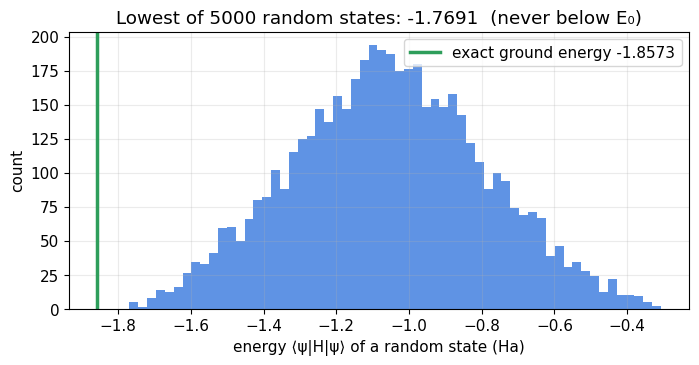

In [15]:
# Variational principle in action: no random state beats the ground state.
E_rand = np.array([random_statevector(4, seed=rng).expectation_value(H_H2).real for _ in range(5000)])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(E_rand, bins=60, color=BLUE, alpha=0.75)
ax.axvline(E0, color=GREEN, lw=2.5, label=f"exact ground energy {E0:.4f}")
ax.set_xlabel("energy ⟨ψ|H|ψ⟩ of a random state (Ha)"); ax.set_ylabel("count"); ax.legend()
ax.set_title(f"Lowest of 5000 random states: {E_rand.min():.4f}  (never below E₀)")
plt.show()
assert E_rand.min() >= E0

Random guessing never gets close to $E_0$ — the lowest of 5000 guesses is still well above it, because the ground state is a needle in a 4-dimensional (complex) haystack, and for larger molecules the haystack is astronomically bigger. We need the parametrized-circuit-plus-optimizer strategy.

## 4.3 The ansatz: a circuit that knows some chemistry

Which states should we try? Chemistry gives a hint. The simplest approximation to the molecule is the **Hartree–Fock (HF)** state: each electron sits in the lowest orbital, ignoring how electrons dodge each other. In our 2-qubit encoding, HF is the basis state $|10\rangle$. The true ground state is HF plus a bit of the "excited" configuration $|01\rangle$ (this mixing is what chemists call **electron correlation**).

So our ansatz only needs to mix those two states:

$$|\psi(\theta)\rangle=\cos\tfrac{\theta}{2}\,|10\rangle+\sin\tfrac{\theta}{2}\,|01\rangle .$$

It has **one parameter**, and $\theta=0$ is exactly Hartree–Fock. The circuit is an $R_y$ rotation, a CNOT and an $X$ gate:

Check: start with $|00\rangle$ → $R_y$ on qubit 0 gives $\cos\frac\theta2|00\rangle+\sin\frac\theta2|01\rangle$ → CNOT (control qubit 0, target qubit 1) gives $\cos\frac\theta2|00\rangle+\sin\frac\theta2|11\rangle$ → $X$ on qubit 1 flips that bit: $\cos\frac\theta2|10\rangle+\sin\frac\theta2|01\rangle$ ✓.

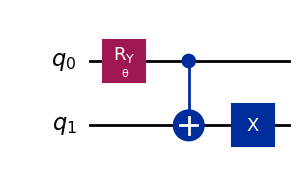

amplitudes (|00>,|01>,|10>,|11>): [0.     0.3894 0.9211 0.    ]
formula                         : [0.     0.3894 0.9211 0.    ]


In [16]:
theta_h = Parameter("θ")
ansatz = QuantumCircuit(2)
ansatz.ry(theta_h, 0)
ansatz.cx(0, 1)
ansatz.x(1)
show_circuit(ansatz)

# Check the state it prepares at θ = 0.8 against the formula cos(θ/2)|10> + sin(θ/2)|01>
sv = Statevector(ansatz.assign_parameters([0.8]))
print("amplitudes (|00>,|01>,|10>,|11>):", np.round(sv.data.real, 4))
print("formula                         :", np.round([0, np.sin(0.4), np.cos(0.4), 0], 4))

### Measuring the energy

$H$ has 5 terms. The constant $g_0 I$ needs no measurement. $Z_0$, $Z_1$ and $Z_0Z_1$ can all be read off from a single batch of measurements in the standard ($Z$) basis. $X_0X_1$ needs a second batch where we first apply a Hadamard to each qubit. So **two measurement settings** give the entire energy:

$$E(\theta)=g_0+g_1\langle Z_0\rangle+g_2\langle Z_1\rangle+g_3\langle Z_0Z_1\rangle+g_4\langle X_0X_1\rangle.$$

We don't build these circuits by hand: exactly as for the single qubit, the `BackendEstimatorV2` primitive (through our `noisy_estimate` helper) finds the groups, appends the basis changes, measures, and combines the averages into one energy. We only supply the ansatz, $H$, $\theta$ and the number of shots per setting.

In [17]:
print("Pauli terms:", len(H_H2), "  ->  measurement settings:", len(H_H2.group_commuting(qubit_wise=True)))

def h2_energy_exact(t):
    """Cost function, infinite-shot limit (what a perfect, noiseless simulator reports)."""
    return float(estimator.run([(ansatz, H_H2, [t])]).result()[0].data.evs)

def h2_energy_shots(t, shots):
    """Cost function the way hardware gives it: `shots` measurements for each measurement setting."""
    return noisy_estimate(ansatz, H_H2, [t], shots)

# consistency checks: Estimator vs. direct state-vector expectation vs. 100000-shot sampling
t_test = 0.8
print("Estimator          :", h2_energy_exact(t_test))
print("Statevector        :", Statevector(ansatz.assign_parameters([t_test])).expectation_value(H_H2).real)
print("100000-shot sample :", h2_energy_shots(t_test, 100000))

# the HF energy and the exact answer, for reference
E_HF = h2_energy_exact(0.0)
print(f"\nHartree–Fock  (θ = 0) : electronic {E_HF:.6f} Ha")
print(f"Exact ground state    : electronic {E0:.6f} Ha")
print(f"Correlation energy    : {E0 - E_HF:.6f} Ha  = what VQE must recover beyond Hartree–Fock")

Pauli terms: 5   ->  measurement settings: 2
Estimator          : -1.4657923908948014
Statevector        : -1.4657923908948012
100000-shot sample : -1.4666284391838056

Hartree–Fock  (θ = 0) : electronic -1.836968 Ha
Exact ground state    : electronic -1.857275 Ha
Correlation energy    : -0.020307 Ha  = what VQE must recover beyond Hartree–Fock


## 4.4 The energy landscape: one parameter

With one parameter the landscape is just a curve, $E(\theta)$. Drag the slider to change the parameter. Left: the energy curve with your current $\theta$ marked. Right: the probabilities of the four basis states, i.e. what the quantum computer would output if you measured. At $\theta=0$ everything is in $|10\rangle$ (Hartree–Fock).

You can also turn on **shot noise** to see what a hardware-like estimate looks like.

In [18]:
thetas = np.linspace(-np.pi, np.pi, 400)
E_curve = estimator.run([(ansatz, H_H2, thetas.reshape(-1, 1))]).result()[0].data.evs   # whole curve in one call
theta_best = thetas[np.argmin(E_curve)]
print(f"Minimum of the curve: E = {E_curve.min():.6f} Ha at θ = {theta_best:.3f} rad  (exact E0 = {E0:.6f})")

def show_h2_curve(theta_=0.0, shots=0):
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
    ax.plot(thetas, E_curve, color=BLUE, lw=2, label="E(θ) exact")
    ax.axhline(E0, color=GREEN, ls="--", label=f"exact ground energy {E0:.4f}")
    ax.axhline(E_HF, color=GRAY, ls=":", label=f"Hartree–Fock {E_HF:.4f}")
    e_now = h2_energy_exact(theta_) if shots == 0 else h2_energy_shots(theta_, shots)
    ax.plot([theta_], [e_now], "o", ms=13, color=ORANGE, mec="k", zorder=5)
    ax.set_xlabel("circuit parameter θ"); ax.set_ylabel("electronic energy (Ha)"); ax.legend(loc="upper center", fontsize=9)
    ax.set_title(f"E = {e_now:+.4f} Ha" + (f"  (estimated from {shots} shots per setting)" if shots else "  (exact)"))
    probs = Statevector(ansatz.assign_parameters([theta_])).probabilities()      # order: 00, 01, 10, 11
    ax2.bar(["|00⟩", "|01⟩", "|10⟩", "|11⟩"], probs, color=[GRAY, ORANGE, BLUE, GRAY])
    ax2.set_ylim(0, 1); ax2.set_ylabel("probability"); ax2.set_title("measurement outcomes of the ansatz")
    plt.tight_layout(); plt.show()

interact(show_h2_curve,
         theta_=FloatSlider(min=-np.pi, max=np.pi, step=0.02, value=0.0, description="θ"),
         shots=SelectionSlider(options=[("exact", 0), ("10", 10), ("100", 100), ("1000", 1000), ("10000", 10000)], value=0, description="shots"));

Minimum of the curve: E = -1.857266 Ha at θ = -0.228 rad  (exact E0 = -1.857275)


interactive(children=(FloatSlider(value=0.0, description='θ', max=3.141592653589793, min=-3.141592653589793, s…

Notice the curve has a single dip, with its lowest point **below** Hartree–Fock and exactly touching the exact ground energy — the one-parameter ansatz is flexible enough to capture the molecule's ground state completely. (In larger molecules, ansätze are never *exactly* right, and the question is how close they get.)

## 4.5 Run the VQE

Now we let the classical optimizer do the work. We start at the Hartree–Fock point $\theta=0$ and let **COBYLA** (a gradient-free optimizer, a sensible choice when evaluations are noisy) tweak $\theta$.

Remember what each cost evaluation represents: *run the two circuits many times on the quantum computer and combine the averages.*

In [19]:
def run_vqe(theta0=0.0, shots=None, maxiter=60):
    """Minimize the H2 energy over theta. shots=None -> exact; otherwise shot-noise estimates."""
    history = []
    def cost(t):
        e = h2_energy_exact(t[0]) if shots is None else h2_energy_shots(t[0], shots)
        history.append((t[0], e))
        return e
    res = minimize(cost, [theta0], method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.5})
    return res, np.array(history)

res, hist = run_vqe(shots=None)
E_vqe = h2_energy_exact(res.x[0])
print(f"VQE optimal θ              : {res.x[0]:+.4f}")
print(f"VQE electronic energy      : {E_vqe:.6f} Ha")
print(f"Exact electronic energy    : {E0:.6f} Ha")
print(f"Error                      : {abs(E_vqe - E0):.2e} Ha   (chemical accuracy is 1.6e-3 Ha)")
print(f"Cost-function evaluations  : {len(hist)}")

VQE optimal θ              : -0.2235
VQE electronic energy      : -1.857275 Ha
Exact electronic energy    : -1.857275 Ha
Error                      : 6.71e-10 Ha   (chemical accuracy is 1.6e-3 Ha)
Cost-function evaluations  : 22


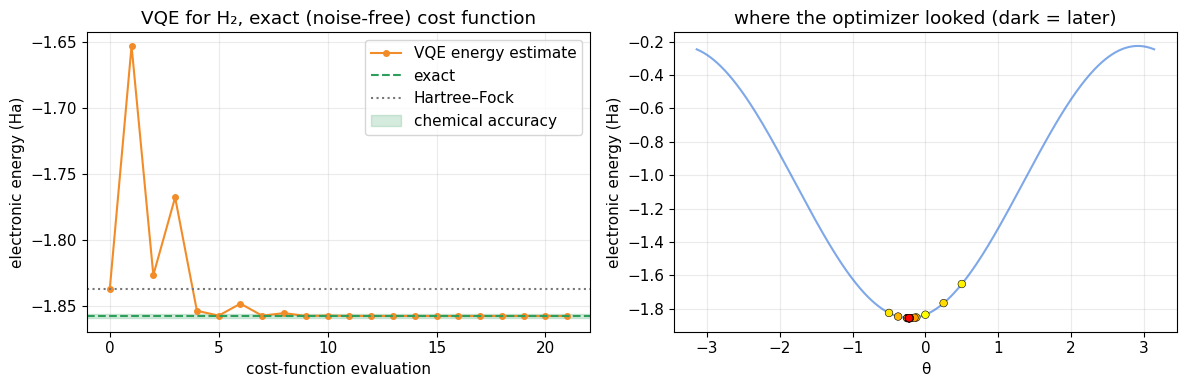

In [20]:
def plot_vqe(hist, title):
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax.plot(hist[:, 1], "o-", color=ORANGE, ms=4, label="VQE energy estimate")
    ax.axhline(E0, color=GREEN, ls="--", label="exact")
    ax.axhline(E_HF, color=GRAY, ls=":", label="Hartree–Fock")
    ax.axhspan(E0 - 1.6e-3, E0 + 1.6e-3, color=GREEN, alpha=0.2, label="chemical accuracy")
    ax.set_xlabel("cost-function evaluation"); ax.set_ylabel("electronic energy (Ha)"); ax.legend(); ax.set_title(title)
    ax2.plot(thetas, E_curve, color=BLUE, alpha=0.6)
    ax2.scatter(hist[:, 0], hist[:, 1], c=np.arange(len(hist)), cmap="autumn_r", s=30, edgecolor="k", linewidth=0.4, zorder=5)
    ax2.set_xlabel("θ"); ax2.set_ylabel("electronic energy (Ha)"); ax2.set_title("where the optimizer looked (dark = later)")
    plt.tight_layout(); plt.show()

plot_vqe(hist, "VQE for H₂, exact (noise-free) cost function")

The energy drops from the Hartree–Fock value to the exact ground-state value within a few dozen evaluations. **That is VQE.**

We can also look at what the quantum computer would output with the optimized circuit: almost all the probability sits on $|10\rangle$ (Hartree–Fock) with a small admixture of $|01\rangle$ — the correlation.

In [ ]:
# What the quantum computer would output for the optimized circuit: sample 4000 shots from the final state
counts_final = Statevector(ansatz.assign_parameters([res.x[0]])).sample_counts(4000)
display(plot_histogram(counts_final, title="Z-basis measurement of the optimized circuit (4000 shots)"))

### Now with realistic measurement noise

A real device only gives finite shots. Use the controls to choose how many shots each measurement setting gets and press **Run** — the energy estimates now jitter. With few shots the optimizer is guided by noise and the final result is only approximate; more shots → better accuracy, at higher cost. (Press Run several times: results differ since the noise is random.)

In [ ]:
def vqe_noisy(shots=1000, start=0.0):
    res_n, hist_n = run_vqe(theta0=start, shots=shots, maxiter=60)
    e_true = h2_energy_exact(res_n.x[0])     # the *true* energy of the state we ended up with
    plot_vqe(hist_n, f"VQE with {shots} shots: final true energy error = {abs(e_true - E0)*1000:.2f} mHa")

interact_manual(vqe_noisy,
                shots=SelectionSlider(options=[10, 30, 100, 300, 1000, 10000], value=1000, description="shots"),
                start=FloatSlider(min=-3, max=3, step=0.1, value=0.0, description="start θ"));

## 4.6 Gradient-based VQE with the parameter-shift rule

For completeness, here's the other strategy from Part 3: gradient descent with the parameter-shift rule, applied to H₂. Since the ansatz has one rotation $R_y(\theta)$, the gradient needs only two extra circuit evaluations per step.

In [ ]:
theta_gd = 0.0
trace = [h2_energy_exact(theta_gd)]
for step in range(30):
    grad = (h2_energy_exact(theta_gd + np.pi/2) - h2_energy_exact(theta_gd - np.pi/2)) / 2    # parameter-shift
    theta_gd -= 0.5 * grad
    trace.append(h2_energy_exact(theta_gd))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.array(trace), "o-", color=ORANGE, ms=4, label="gradient descent (parameter-shift)")
ax.axhline(E0, color=GREEN, ls="--", label="exact"); ax.axhline(E_HF, color=GRAY, ls=":", label="Hartree–Fock")
ax.set_xlabel("iteration"); ax.set_ylabel("electronic energy (Ha)"); ax.legend(); plt.show()
print(f"Final electronic energy: {trace[-1]:.6f} Ha   (exact {E0:.6f} Ha),   θ = {theta_gd:.4f}")

---
# Wrap-up

| Idea | Where we saw it |
|---|---|
| Optimization = tune parameters to minimize a cost | Part 1 |
| Gradient descent and other optimizers; local minima; cost per evaluation | Part 2 |
| Energy $\langle\psi(\theta)|H|\psi(\theta)\rangle$ as a cost function; parametrized circuits; Bloch-sphere picture; measuring Pauli strings with shots; parameter-shift gradients | Part 3 |
| Variational principle guarantees $E(\theta)\ge E_0$; molecular Hamiltonian as a sum of Pauli strings; ansatz; VQE loop; shot noise | Part 4 |

**Qiskit tools we used:** `QuantumCircuit` + `Parameter` (circuits with knobs), `PauliEvolutionGate` (exponentials of Pauli sums), `SparsePauliOp` (Hamiltonians), `Statevector` (states), `StatevectorEstimator` (exact $\langle H\rangle$), `BackendEstimatorV2` + `BasicSimulator` (shot-based $\langle H\rangle$ by measuring Pauli strings), `group_commuting` (how many measurement settings), `transpile` (compilation), `plot_histogram`.

**The VQE recipe**
1. Write the problem as a Hamiltonian $H=\sum_k c_k P_k$ (Pauli strings $P_k$).
2. Choose an ansatz circuit $U(\vec\theta)$ that prepares $|\psi(\vec\theta)\rangle$.
3. On the quantum computer: prepare the state, measure each group of Pauli terms, combine into $E(\vec\theta)$.
4. On the classical computer: update $\vec\theta$ to lower $E$.
5. Repeat until the energy stops decreasing.

**Why it's not a solved problem** (where research is happening)
* **Ansatz design:** too simple → can't reach the ground state; too flexible → hard to train ("barren plateaus"). Chemistry-inspired ansätze (UCCSD, ADAPT-VQE) and hardware-efficient ansätze are popular choices — see the reading list below.
* **Noise:** real devices have gate and readout errors as well as shot noise (we only simulated shot noise here).
* **Measurement cost:** big molecules have thousands of Pauli terms.
* **Local minima:** just like Part 2.

## Exercises
1. **Part 1–2:** In the 2D gradient-descent widget, find a start point where the descent ends in the *local* minimum, and one where it ends in the global one. Which learning rate makes it unstable?
2. **Part 3:** Change `H1` to `SparsePauliOp.from_list([("Z", 0.6), ("Y", 0.8)])` and rerun Part 3 from that cell on. Where is the new minimum on the Bloch sphere? (The `closed_form` comparison printed there only holds for the original `H`.) How many measurement settings does `group_commuting` report now?
3. **Part 3:** Use `energy1_shots` instead of `energy1` inside `optimize_qubit` (pass `cost=lambda t, p: energy1_shots(t, p, 200)`). How many shots do you need for a smooth descent?
4. **Part 4:** Change the starting θ in `run_vqe` to `np.pi`. Does VQE still find the ground state? Why?
5. **Part 4:** Replace `g4` by `0.5` before building `H_H2` (a stronger coupling). How does the gap between Hartree–Fock and the exact ground energy change?
6. **Part 4:** Build a *two*-parameter ansatz by adding `ansatz.ry(Parameter("α"), 1)` at the start. Does it find a lower energy than the exact ground state? (It can't — why?)
7. **Part 4:** Run `run_vqe(shots=1000)` a few times. Using the number of measurement settings of $H_{H_2}$, how many total shots does one VQE run use? How does the final *true* energy error change if you use 100 shots instead?
8. **Part 5:** In the table of ansätze, which single knob would you keep if you could only afford one? Check by running `run_vqe_he(active=(0,))`, `(1,)` and `(2,)`.
9. **Part 5:** Run the noisy VQE with 9000 instead of 90000 shots per setting. Do you still reach chemical accuracy? How many total shots did you save?
10. **Part 5:** Replace the chemistry-inspired circuit by a generic *hardware-efficient* circuit, e.g. `qiskit.circuit.library.RealAmplitudes(4, reps=2)`, and run COBYLA from a random start. Which energy does it find, and does it have 2 electrons? (Such a circuit does not preserve the electron number.)

## Reading list

Gentle starting points first; the original research papers are listed for the curious.

**VQE in general**
* [Variational quantum eigensolver — IBM Quantum tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/variational-quantum-eigensolver): a short, code-first walk-through of exactly the loop we built.
* [Tilly *et al.*, "The Variational Quantum Eigensolver: a review of methods and best practices"](https://arxiv.org/abs/2111.05176): a long but readable review of every ingredient of VQE.

**Hardware-efficient circuits** (ansätze built from the gates and connectivity a device offers, not from chemistry)
* [IBM Quantum Learning — "Variational algorithm design"](https://quantum.cloud.ibm.com/learning/en/courses/variational-algorithm-design): the lesson on ansätze and variational forms introduces hardware-efficient circuits such as `EfficientSU2` and the trade-off between expressiveness and depth.
* [Classiq — "Circuit of the month: a hardware-efficient variational circuit"](https://www.classiq.io/insights/generating-a-hardware-efficient-ansatz): a short, gentle article on what a hardware-efficient ansatz is and how one is generated.
* [Kandala *et al.*, Nature 2017](https://arxiv.org/abs/1704.05018): the paper that introduced the idea in VQE experiments (more technical).

**Barren plateaus** (landscapes that become exponentially flat as circuits grow)
* [PennyLane demo — "Barren plateaus in quantum neural networks"](https://pennylane.ai/qml/demos/tutorial_barren_plateaus): hands-on code showing the gradients vanish as you add qubits; the best place to *see* the effect yourself (assumes you know what a variational circuit is).
* [Larocca *et al.*, "Barren plateaus in variational quantum computing", Nature Reviews Physics 2025](https://www.nature.com/articles/s42254-025-00813-9): an accessible review of why they appear and how to avoid them.
* [McClean *et al.*, 2018](https://arxiv.org/abs/1803.11173): the original paper.

**ADAPT-VQE** (grow the circuit one gate at a time instead of fixing it in advance)
* [PennyLane demo — "Adaptive circuits for quantum chemistry"](https://pennylane.ai/qml/demos/tutorial_adaptive_circuits): explains the idea step by step — compute the gradient of every candidate excitation, keep the best one, optimize, repeat — with a worked molecule. It is the natural continuation of Part 5.
* [Grimsley *et al.*, "An adaptive variational algorithm for exact molecular simulations on a quantum computer"](https://arxiv.org/abs/1812.11173): the original ADAPT-VQE paper.